# Loan Approval Analysis

**Business question:** What decides whether a home loan application is approved, and could the approval decision be automated?

**Data:** 614 past loan applications from a housing finance company: applicant demographics, income, loan amount and term, credit history, property area, and whether the loan was approved.

## Summary of findings

1. **69% of applications were approved** (422 of 614).
2. **Credit history decides almost everything.** Applicants who meet credit guidelines are approved about 80% of the time; those who don't are approved about 8% of the time.
3. **Income makes no difference.** Approval rates are flat across every income band, even after combining applicant and co-applicant income and comparing the monthly instalment to income.
4. **Location matters a little.** Semi-urban applicants are approved more often (77%) than urban (66%) or rural (61%) applicants.
5. **A one-line rule matches machine learning.** "Approve if credit history is good" performs about as well as logistic regression and random forest in cross-validation.
6. **Missing credit history should not be treated as good.** 50 applicants have no credit history recorded. Filling these with the most common value (good) hides a group with its own approval rate.

**Recommendation:** Use credit history as the first screening step, flag missing credit history for manual review, and investigate why income plays no visible role in approvals.

## 1. Setup

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

import os
sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)
RANDOM_STATE = 42
TEAL, AMBER, GREY = "#1F5F6B", "#B87A12", "#C9D4DC"

## 2. Load the data

In [2]:
df = pd.read_csv("loanprediction.csv")
print(df.shape)
df.head()

(614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [4]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


## 3. Data quality

### 3.1 Missing values

In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(1)})

,missing,percent
Credit_History,50,8.1
Self_Employed,32,5.2
LoanAmount,22,3.6
Dependents,15,2.4
Loan_Amount_Term,14,2.3
Gender,13,2.1
Married,3,0.5


Seven columns have gaps. The most important is **Credit_History** (50 applicants, 8%), because it turns out to be the strongest driver of approval.

Instead of filling missing values with the mode or median straight away, I first check whether "missing" behaves differently. If it does, it should be kept as its own category.

In [6]:
df["approved"] = (df["Loan_Status"] == "Y").astype(int)
df["Credit_History_Status"] = df["Credit_History"].map({1.0: "Meets guidelines", 0.0: "Does not meet"}).fillna("Unknown")
df.groupby("Credit_History_Status")["approved"].agg(approval_rate="mean", applicants="count").round(3)

,approval_rate,applicants
Credit_History_Status,,
Does not meet,0.079,89
Meets guidelines,0.796,475
Unknown,0.740,50


Applicants with **unknown** credit history are approved 74% of the time. That is close to, but not the same as, the 80% for applicants with a good history, and nowhere near the 8% for those with a bad one. Filling these 50 gaps with the mode (1 = good) would quietly treat them as good borrowers. I keep "Unknown" as a separate category.

### 3.2 Duplicates, identifiers and value checks

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Loan IDs:", df["Loan_ID"].duplicated().sum())
print("Loan terms (months):", sorted(df["Loan_Amount_Term"].dropna().unique()))
print("Applicants with zero co-applicant income:", (df["CoapplicantIncome"] == 0).sum())

Duplicate rows: 0
Duplicate Loan IDs: 0
Loan terms (months): [np.float64(12.0), np.float64(36.0), np.float64(60.0), np.float64(84.0), np.float64(120.0), np.float64(180.0), np.float64(240.0), np.float64(300.0), np.float64(360.0), np.float64(480.0)]
Applicants with zero co-applicant income: 273


No duplicates. Most loans are for 360 months (30 years). `Loan_ID` is just an identifier, so it is excluded from the analysis. `LoanAmount` is in thousands.

### 3.3 Features that reflect affordability

A lender cares less about income alone than about whether the applicant can afford the repayments. I create:
- **Total_Income:** applicant plus co-applicant income
- **EMI:** approximate monthly instalment (loan amount ÷ term, ignoring interest)
- **EMI_to_Income:** the share of monthly income the instalment would take

In [8]:
df["Total_Income"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df["EMI"] = df["LoanAmount"] * 1000 / df["Loan_Amount_Term"]
df["EMI_to_Income"] = df["EMI"] / df["Total_Income"]
df[["Total_Income", "EMI", "EMI_to_Income"]].describe().round(3)

,Total_Income,EMI,EMI_to_Income
count,614.000,578.000,578.000
mean,7024.705,480.300,0.078
std,6458.664,525.459,0.081
min,1442.000,25.000,0.007
25%,4166.000,286.111,0.056
50%,5416.500,365.278,0.069
75%,7521.750,513.889,0.082
max,81000.000,9250.000,1.237


## 4. What drives approval?

### 4.1 Approval rate by applicant group

I compare **approval rates**, not counts. Counts mainly show which group is bigger (there are 3.6× more graduates than non-graduates); rates show which group is more likely to be approved.

Overall approval rate: 68.7% (422 of 614)


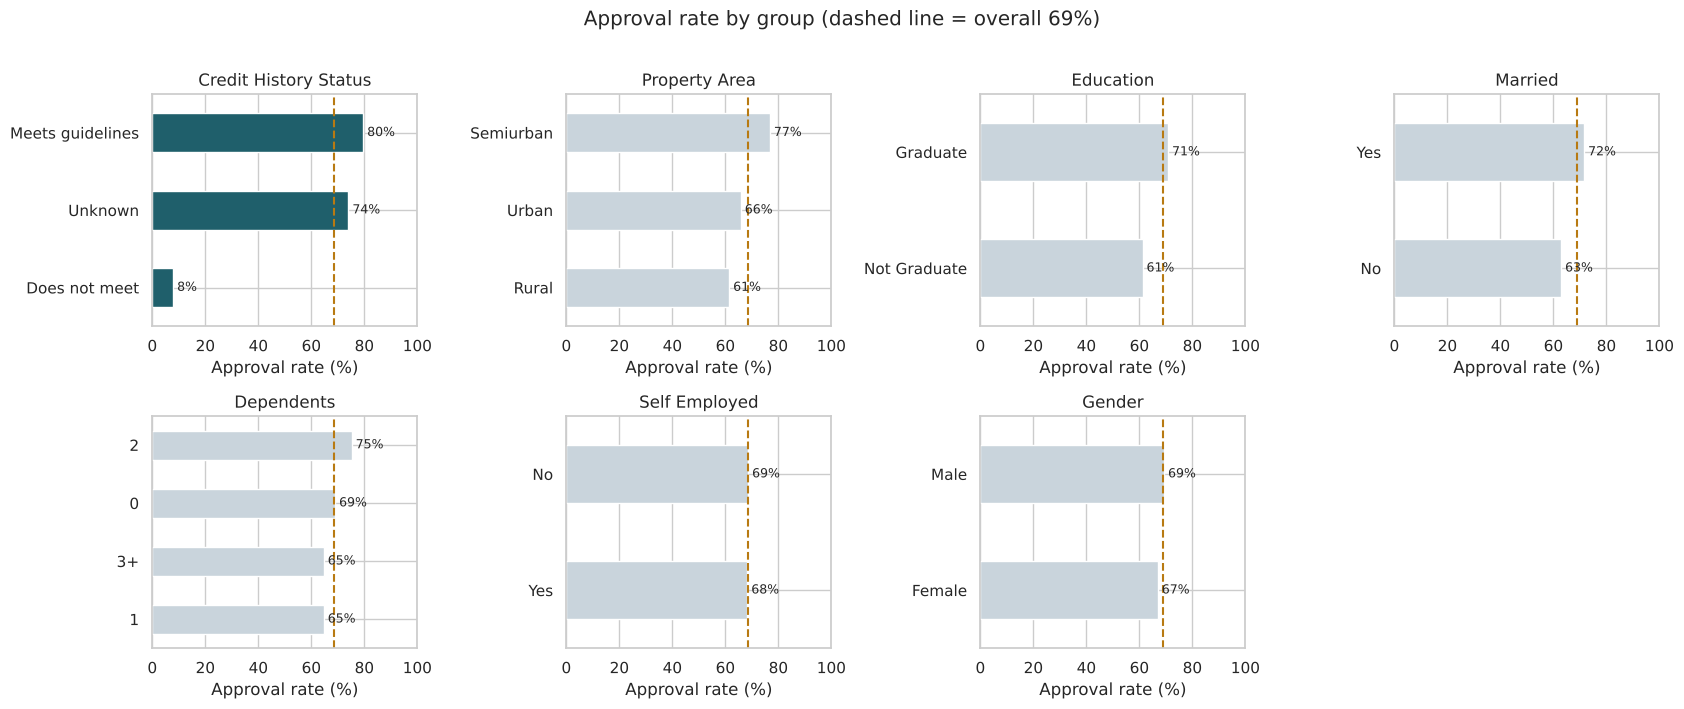

In [9]:
overall = df["approved"].mean()
print(f"Overall approval rate: {overall:.1%} ({df['approved'].sum()} of {len(df)})")

groups = ["Credit_History_Status", "Property_Area", "Education", "Married", "Dependents", "Self_Employed", "Gender"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), groups):
    rates = df.groupby(col)["approved"].mean().sort_values() * 100
    colors = [TEAL if col == "Credit_History_Status" else GREY] * len(rates)
    rates.plot.barh(ax=ax, color=colors)
    ax.axvline(overall * 100, color=AMBER, linestyle="--", linewidth=1.5)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Approval rate (%)")
    ax.set_ylabel("")
    ax.set_title(col.replace("_", " "))
    for i, v in enumerate(rates):
        ax.text(v + 1.5, i, f"{v:.0f}%", va="center", fontsize=9)
axes.ravel()[-1].axis("off")
fig.suptitle(f"Approval rate by group (dashed line = overall {overall:.0%})", y=1.01)
plt.tight_layout()
plt.savefig("images/approval_by_group.png", dpi=150, bbox_inches="tight")
plt.show()

Credit history stands out. Every other group sits within about 10 points of the overall rate.

### 4.2 Does income matter?

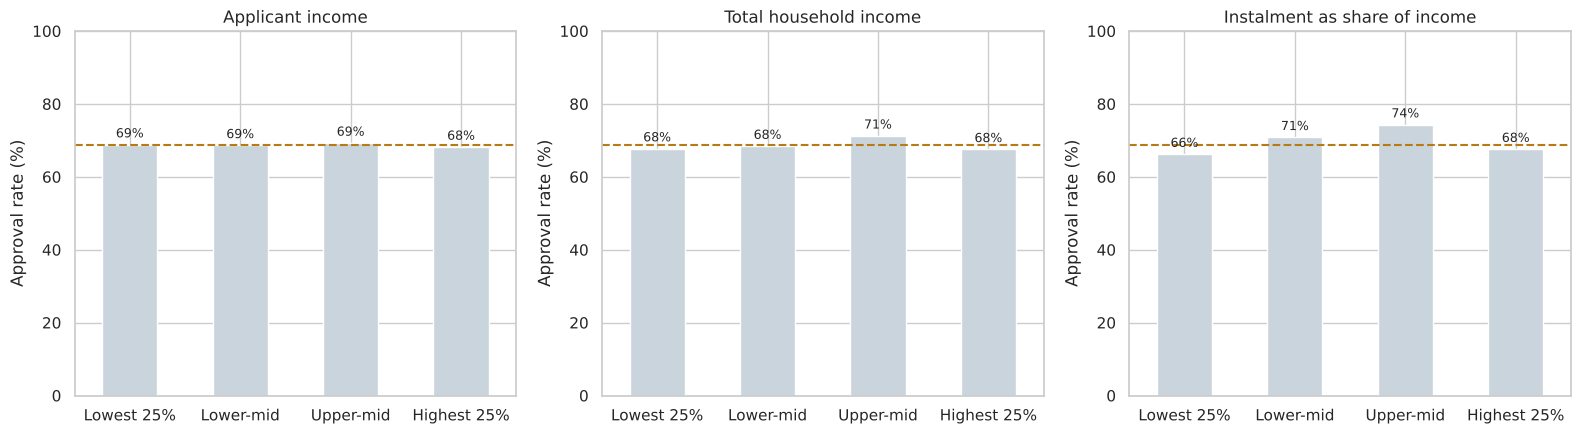

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, label in zip(axes,
                          ["ApplicantIncome", "Total_Income", "EMI_to_Income"],
                          ["Applicant income", "Total household income", "Instalment as share of income"]):
    bands = pd.qcut(df[col], 4, labels=["Lowest 25%", "Lower-mid", "Upper-mid", "Highest 25%"])
    rates = df.groupby(bands, observed=True)["approved"].mean() * 100
    rates.plot.bar(ax=ax, color=GREY, rot=0)
    ax.axhline(overall * 100, color=AMBER, linestyle="--", linewidth=1.5)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Approval rate (%)")
    ax.set_xlabel("")
    ax.set_title(label)
    for i, v in enumerate(rates):
        ax.text(i, v + 2, f"{v:.0f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("images/approval_by_income.png", dpi=150, bbox_inches="tight")
plt.show()

Approval rates are flat across income bands, whether I use applicant income, household income, or the instalment-to-income ratio. On this data, how much an applicant earns does not visibly change their chances. That is surprising for a lender, and worth raising with the business: either income is checked earlier in the process (so only eligible applicants reach this stage), or affordability is not being weighed.

### 4.3 Credit history and location together

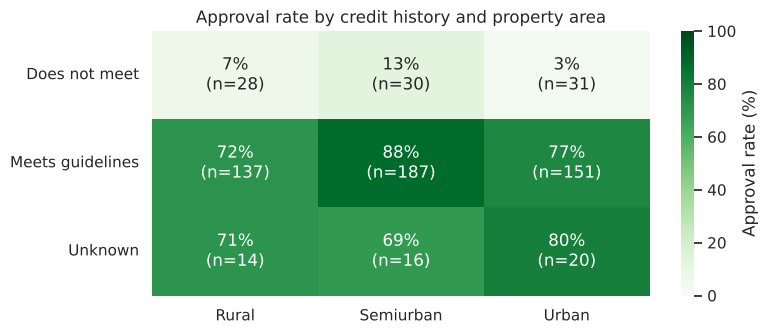

In [11]:
pivot = pd.pivot_table(df, values="approved", index="Credit_History_Status", columns="Property_Area", aggfunc="mean") * 100
counts = pd.pivot_table(df, values="approved", index="Credit_History_Status", columns="Property_Area", aggfunc="count")
plt.figure(figsize=(8, 3.5))
sns.heatmap(pivot, annot=pivot.round(0).astype(int).astype(str) + "%\n(n=" + counts.astype(str) + ")",
            fmt="", cmap="Greens", vmin=0, vmax=100, cbar_kws={"label": "Approval rate (%)"})
plt.title("Approval rate by credit history and property area")
plt.ylabel("")
plt.xlabel("")
plt.tight_layout()
plt.show()

Within every area, credit history dominates. Among applicants with a good history, semi-urban applicants still do best (around 88%), so the location effect is real but secondary.

## 5. Statistical tests

- **Categorical features:** chi-square test, with Cramér's V for the strength of the association (0.1 = small, 0.3 = medium, 0.5 = large).
- **Numeric features:** Mann-Whitney U test comparing approved and rejected applicants (income data is heavily skewed, so I avoid tests that assume a normal distribution).

In [12]:
rows = []
for col in ["Credit_History_Status", "Property_Area", "Married", "Education", "Dependents", "Gender", "Self_Employed"]:
    table = pd.crosstab(df[col], df["approved"])
    chi2, p, dof, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"feature": col, "test": "Chi-square", "p_value": p, "effect_size": v})

for col in ["ApplicantIncome", "CoapplicantIncome", "Total_Income", "LoanAmount", "EMI_to_Income"]:
    a = df.loc[df["approved"] == 1, col].dropna()
    r = df.loc[df["approved"] == 0, col].dropna()
    u, p = mannwhitneyu(a, r)
    rows.append({"feature": col, "test": "Mann-Whitney U", "p_value": p, "effect_size": abs(1 - 2 * u / (len(a) * len(r)))})

tests = pd.DataFrame(rows).sort_values("effect_size", ascending=False)
tests["significant (p < 0.05)"] = np.where(tests["p_value"] < 0.05, "Yes", "No")
tests["strength"] = pd.cut(tests["effect_size"], [0, 0.1, 0.3, 0.5, 1], labels=["Negligible", "Small", "Medium", "Large"], include_lowest=True)
tests.round(4)

,feature,test,p_value,effect_size,significant (p < 0.05),strength
0,Credit_History_Status,Chi-square,0.0000,0.5415,Yes,Large
1,Property_Area,Chi-square,0.0021,0.1415,Yes,Small
2,Married,Chi-square,0.0344,0.0856,Yes,Negligible
3,Education,Chi-square,0.0431,0.0816,Yes,Negligible
4,Dependents,Chi-square,0.3679,0.0726,No,Negligible
10,LoanAmount,Mann-Whitney U,0.3952,0.0438,No,Negligible
8,CoapplicantIncome,Mann-Whitney U,0.3869,0.0416,No,Negligible
9,Total_Income,Mann-Whitney U,0.7128,0.0185,No,Negligible
5,Gender,Chi-square,0.7087,0.0152,No,Negligible
7,ApplicantIncome,Mann-Whitney U,0.9181,0.0052,No,Negligible


Credit history has a **large** effect. Property area has a small one. Education and marital status are only borderline, and every income measure is negligible. This confirms what the charts show.

## 6. The same questions in SQL

Much of this analysis would normally run against a database. Here I load the data into SQLite and answer the key questions with SQL.

In [13]:
conn = sqlite3.connect(":memory:")
df.drop(columns=["Credit_History_Status"]).to_sql("loans", conn, index=False)

def sql(query):
    return pd.read_sql_query(query, conn)

In [14]:
# Approval rate by credit history, with missing values kept as their own group
sql('''
SELECT
    CASE
        WHEN Credit_History = 1 THEN 'Meets guidelines'
        WHEN Credit_History = 0 THEN 'Does not meet'
        ELSE 'Unknown'
    END                                   AS credit_history,
    COUNT(*)                              AS applicants,
    SUM(Loan_Status = 'Y')                AS approved,
    ROUND(100.0 * AVG(Loan_Status = 'Y'), 1) AS approval_rate_pct
FROM loans
GROUP BY 1
ORDER BY approval_rate_pct DESC
''')

,credit_history,applicants,approved,approval_rate_pct
0,Meets guidelines,475,378,79.6
1,Unknown,50,37,74.0
2,Does not meet,89,7,7.9


In [15]:
# Approval rate by property area among applicants with a good credit history,
# compared with the overall rate using a window function
sql('''
WITH area AS (
    SELECT Property_Area,
           COUNT(*)               AS applicants,
           AVG(Loan_Status = 'Y') AS approval_rate
    FROM loans
    WHERE Credit_History = 1
    GROUP BY Property_Area
)
SELECT Property_Area,
       applicants,
       ROUND(100 * approval_rate, 1)                                     AS approval_rate_pct,
       ROUND(100 * (approval_rate - AVG(approval_rate) OVER ()), 1)      AS vs_average_pts,
       RANK() OVER (ORDER BY approval_rate DESC)                         AS rank
FROM area
''')

,Property_Area,applicants,approval_rate_pct,vs_average_pts,rank
0,Semiurban,187,87.7,9.0,1
1,Urban,151,76.8,-1.9,2
2,Rural,137,71.5,-7.2,3


In [16]:
# Income quartiles with NTILE: does approval rise with household income?
sql('''
WITH banded AS (
    SELECT ApplicantIncome + CoapplicantIncome            AS total_income,
           Loan_Status,
           NTILE(4) OVER (ORDER BY ApplicantIncome + CoapplicantIncome) AS income_quartile
    FROM loans
)
SELECT income_quartile,
       MIN(total_income)                         AS from_income,
       MAX(total_income)                         AS to_income,
       COUNT(*)                                  AS applicants,
       ROUND(100.0 * AVG(Loan_Status = 'Y'), 1)  AS approval_rate_pct
FROM banded
GROUP BY income_quartile
ORDER BY income_quartile
''')

,income_quartile,from_income,to_income,applicants,approval_rate_pct
0,1,1442.0,4166.0,154,68.2
1,2,4166.0,5417.0,154,68.2
2,3,5417.0,7535.0,153,70.6
3,4,7541.0,81000.0,153,68.0


## 7. Could approvals be automated?

I compare five approaches with **5-fold stratified cross-validation**. With only 614 applications, a single train/test split would be unreliable, so every model is trained and tested five times on different folds.

1. **Baseline:** approve everyone (the majority class)
2. **Simple rule:** approve if credit history meets guidelines (unknown counts as approve)
3. **Logistic regression**
4. **Decision tree** (limited to 3 levels so it stays readable)
5. **Random forest**

All preprocessing happens inside a pipeline, so imputation and scaling are learned from the training folds only. Categorical features are one-hot encoded, and missing categories are kept as "Unknown".

In [17]:
categorical = ["Credit_History_Status", "Property_Area", "Education", "Married", "Dependents", "Gender", "Self_Employed"]
numeric = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "EMI_to_Income"]

X = df[categorical + numeric].copy()
X[categorical] = X[categorical].fillna("Unknown")
y = df["approved"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                      ("scale", StandardScaler())]), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

class CreditHistoryRule(DummyClassifier):
    """Approve unless credit history does not meet guidelines."""
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        return self
    def predict(self, X):
        return (X["Credit_History_Status"] != "Does not meet").astype(int).to_numpy()
    def predict_proba(self, X):
        p = self.predict(X).astype(float)
        return np.column_stack([1 - p, p])

models = {
    "Baseline: approve everyone": Pipeline([("model", DummyClassifier(strategy="most_frequent"))]),
    "Rule: credit history only": Pipeline([("model", CreditHistoryRule())]),
    "Logistic Regression": Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))]),
    "Decision Tree (depth 3)": Pipeline([("prep", preprocess), ("model", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("prep", preprocess), ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "roc_auc": "roc_auc"}

results = {}
for name, model in models.items():
    s = cross_validate(model, X, y, cv=cv, scoring=scoring)
    results[name] = {m: s[f"test_{m}"].mean() for m in scoring} | {"accuracy_std": s["test_accuracy"].std()}

scores = pd.DataFrame(results).T[["accuracy", "accuracy_std", "precision", "recall", "roc_auc"]]
scores.round(3)

,accuracy,accuracy_std,precision,recall,roc_auc
Baseline: approve everyone,0.687,0.004,0.687,1.000,0.500
Rule: credit history only,0.809,0.016,0.791,0.983,0.705
Logistic Regression,0.798,0.020,0.788,0.967,0.748
Decision Tree (depth 3),0.803,0.020,0.789,0.974,0.698
Random Forest,0.806,0.018,0.790,0.979,0.757


**How to read this:**
- **Precision:** of the loans the model approves, how many were actually approved. For a lender, this is the closest measure to "how many bad loans slip through".
- **Recall:** of the loans that were approved, how many the model would also approve.
- **ROC-AUC:** how well the model ranks applicants overall (0.5 = random, 1.0 = perfect). The single rule gets a modest ROC-AUC because it only gives two possible scores.

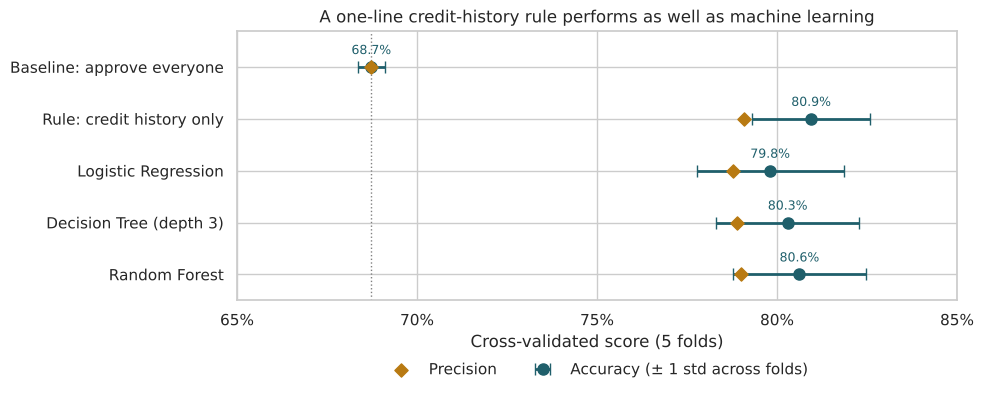

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.2))
order = scores.index[::-1]
ypos = np.arange(len(order))
ax.errorbar(scores.loc[order, "accuracy"], ypos, xerr=scores.loc[order, "accuracy_std"],
            fmt="o", color=TEAL, ecolor=TEAL, elinewidth=2, capsize=4, markersize=8, label="Accuracy (± 1 std across folds)")
ax.scatter(scores.loc[order, "precision"], ypos, marker="D", color=AMBER, s=45, zorder=3, label="Precision")
ax.axvline(scores.loc["Baseline: approve everyone", "accuracy"], color="grey", linestyle=":", linewidth=1)
for y_, acc in zip(ypos, scores.loc[order, "accuracy"]):
    ax.text(acc, y_ + 0.25, f"{acc:.1%}", ha="center", fontsize=9, color=TEAL)
ax.set_yticks(ypos)
ax.set_yticklabels(order)
ax.set_xlim(0.65, 0.85)
ax.set_xticks([0.65, 0.70, 0.75, 0.80, 0.85])
ax.set_ylim(-0.5, len(order) - 0.3)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Cross-validated score (5 folds)")
ax.set_title("A one-line credit-history rule performs as well as machine learning")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.1 What the decision tree learned

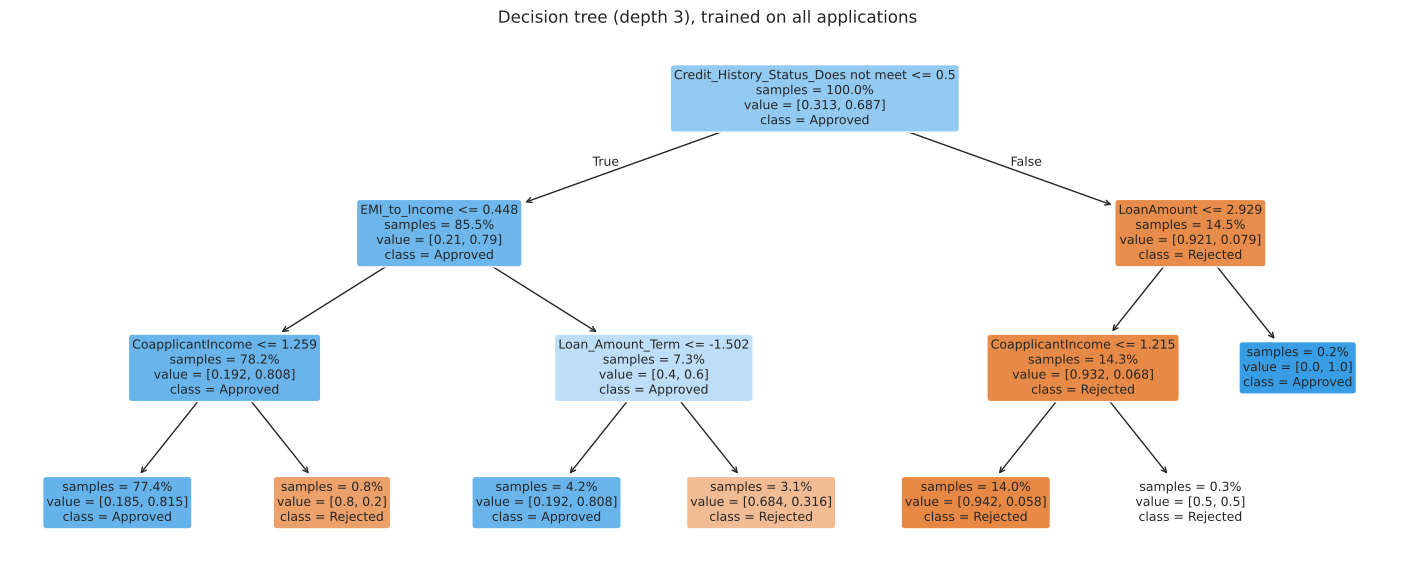

In [19]:
tree_model = models["Decision Tree (depth 3)"].fit(X, y)
names = [n.replace("num__", "").replace("cat__", "") for n in tree_model.named_steps["prep"].get_feature_names_out()]
plt.figure(figsize=(18, 7))
plot_tree(tree_model.named_steps["model"], feature_names=names, class_names=["Rejected", "Approved"],
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Decision tree (depth 3), trained on all applications")
plt.show()

The first split is credit history, and it does almost all the work. The deeper splits make only small changes, which is why the tree performs about the same as the one-line rule.

## 8. Conclusions

1. **Credit history is the deciding factor.** 80% of applicants who meet credit guidelines are approved, against 8% of those who don't. No other feature comes close.
2. **Income does not visibly affect approval**, even when measured as household income or as the instalment-to-income ratio.
3. **Semi-urban applicants are approved more often**, and this holds within the good-credit group.
4. **Machine learning adds little over a single rule.** Logistic regression, decision tree and random forest all score close to the credit-history rule in cross-validation.
5. **How missing values are handled changes the story.** Treating the 50 missing credit histories as "good" (mode imputation) would hide a group with its own approval pattern.

## 9. Recommendations

- **Use credit history as the first, automatic screening step.** It is transparent, easy to explain to applicants and regulators, and as accurate as the models tested.
- **Send applications with missing credit history for manual review** instead of assuming they are good.
- **Review the role of affordability.** If income really has no effect on approvals, the company may be approving loans that applicants struggle to repay. Combining this data with repayment outcomes would show whether that is happening.
- **Investigate the semi-urban advantage.** It may reflect local branch policy, property values or demand, and could point to an underserved rural market.

## 10. Limitations

- 614 applications is a small sample, so group-level rates (for example, 51 applicants with 3+ dependents) carry wide uncertainty.
- The data shows approvals, not repayments. A model that copies past approval decisions also copies any past mistakes or bias.
- `LoanAmount` and income units are not documented; EMI ignores interest.